# Practical 1 report: preparing biological data for machine learning

**Student:** Valeriia  
**Date:** 24 October 2026  
**Practical:** 1 - Data to ML-ready format

## 2. Data-preparation readiness

Complete this section before describing modelling results.

## Scientific purpose and provenance

**- [x] Is the biological question and prediction task stated clearly?**  
Can the levels of cortex nuclear proteins predict the `Behavior` label (C/S vs S/C) of a mouse that was not used for training?  

**- [x] Is the unit of observation clear (for example, patient, tissue, cell, mouse, or technical measurement)?**  
One row is one RPPA technical measurement of one mouse's sample; the independent biological unit is the mouse  

**- [x] Have I recorded the data version, processing history, and transformations already applied?**  
The source (UCI dataset 342, file `Data_Cortex_Nuclear.xls`, sheet `Hoja1`) and every transformation I apply are recorded in the code

In [1]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, scipy
from scipy.stats import fisher_exact
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold, KFold, StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [7]:
DATA = Path("/home/valerie/Desktop/Master/ml/KSE_ML_for_bioinformatics/practicals/week1") # folder that contains the .xls file
RANDOM_STATE = 230926
FILE = DATA / "Data_Cortex_Nuclear.xls"

df_mice = pd.read_excel(FILE)
df_mice["mouse_id"] = df_mice["MouseID"].astype(str).str.rsplit("_", n=1).str[0]

meta_cols = ["MouseID", "mouse_id", "Genotype", "Treatment", "Behavior", "class"]
protein_cols = [c for c in df_mice.columns if c not in meta_cols]
X_all = df_mice[protein_cols]

print("File:", FILE.name, "| sheets:", pd.ExcelFile(FILE).sheet_names)
print("Table:", df_mice.shape, "= 82 original columns + derived mouse_id")
print("Protein columns:", len(protein_cols), "| metadata/identifier columns:", len(meta_cols))
print("Only transformation so far: mouse_id derived from MouseID (text before the last underscore)")

File: Data_Cortex_Nuclear.xls | sheets: ['Hoja1']
Table: (1080, 83) = 82 original columns + derived mouse_id
Protein columns: 77 | metadata/identifier columns: 6
Only transformation so far: mouse_id derived from MouseID (text before the last underscore)


## Table shape and identifiers

**- [x] Is the table tidy: one observation per row, one variable per column, and one value per cell?**  
Yes at the level of measurements; the rows are not independent observations of mice.  

**- [x] If the original assay has features in rows and samples in columns, have I transposed it into the format expected by the analysis tool?**  
Not needed: the file already has measurements in rows and proteins in columns.  

**- [x] Are row names, column names, and identifiers clear, unique, stable, and free from accidental index columns?**  
`MouseID` is unique for all 1080 rows and there are no index-like columns.

**- [x] Can every feature and observation be traced back to its source?**  
`MouseID` = `mouse_id` + measurement suffix; protein columns keep their original names.  

**- [ ] Are the feature matrix and metadata aligned by an explicit identifier rather than by row order?**  
Features and metadata live in one table; `X`, `y` and `groups` are all taken from the same dataframe, and the split is checked by `mouse_id`, not by position. How the protein values were normalised upstream is not documented in the file. I guess more information could be obtain from the corresponding article, but as I understood the assignment is about the work with only the given information to simulate the real dataset. Sorry if I am wrong and I had to work with article instead.

In [3]:
print("MouseID unique per row:", df_mice["MouseID"].is_unique, f"({df_mice['MouseID'].nunique()} unique of {len(df_mice)} rows)")
print("Unnamed / index-like columns:", [c for c in df_mice.columns if str(c).startswith("Unnamed")])
print("Orientation: samples in rows, proteins in columns ->", X_all.shape, "(no transpose needed)")
print("Rows per mouse:", df_mice.groupby("mouse_id").size().value_counts().to_dict())
const = df_mice.groupby("mouse_id")[["Genotype", "Treatment", "Behavior", "class"]].nunique().max()
print("Max distinct values per mouse (1 = label constant within a mouse):", const.to_dict())

MouseID unique per row: True (1080 unique of 1080 rows)
Unnamed / index-like columns: []
Orientation: samples in rows, proteins in columns -> (1080, 77) (no transpose needed)
Rows per mouse: {15: 72}
Max distinct values per mouse (1 = label constant within a mouse): {'Genotype': 1, 'Treatment': 1, 'Behavior': 1, 'class': 1}


## Types, values, and measurement meaning

**- [x] Are numerical, categorical, ordinal, text, date, and identifier columns correctly classified?**  
77 numerical protein columns (float64); `Genotype`, `Treatment`, `Behavior`, `class` are nominal categories; `MouseID` and `mouse_id` are identifiers; there are no date or text columns.

**- [ ] Are units, scales, encodings, reference categories, and detection limits understood?**
Partly. Protein values are protein levels in arbitrary units; units, detection limits and the meaning of the `_N` suffix are not described in the task or in the file. Again, srry if I am wrong and I had to work with article text.

**- [x] Have I checked impossible values, inconsistent labels, unexpected categories, constant features, and extreme values?**
No infinities, zeros or constant columns; labels are consistent; one slightly negative value (`RRP1_N`, row 298, -0.062); one mouse (3484) with extreme levels of several proteins; `ARC_N` and `pS6_N` are identical.

**- [ ] Are normalization, scaling, log transformation, and batch-correction steps documented?**
Not for the upstream data. The only scaling I apply is `StandardScaler` for the exploratory PCA.

In [8]:
print("Protein dtypes:", X_all.dtypes.value_counts().to_dict())
print("Categorical levels:", {c: sorted(df_mice[c].unique()) for c in ["Genotype", "Treatment", "Behavior", "class"]})
print("Infinite values:", int(np.isinf(X_all.to_numpy(dtype=float)).sum()),
      "| negative values:", int((X_all < 0).sum().sum()),
      "| zeros:", int((X_all == 0).sum().sum()),
      "| constant columns:", int((X_all.nunique() <= 1).sum()))
stacked = X_all.stack()
print("Negative value(s) [(row, protein): value]:", stacked[stacked < 0].round(4).to_dict())
print("Value range:", round(float(X_all.min().min()), 3), "to", round(float(X_all.max().max()), 3))
display(X_all.describe().T[["min", "50%", "max"]].sort_values("max", ascending=False).head(5).round(3))

Protein dtypes: {dtype('float64'): 77}
Categorical levels: {'Genotype': ['Control', 'Ts65Dn'], 'Treatment': ['Memantine', 'Saline'], 'Behavior': ['C/S', 'S/C'], 'class': ['c-CS-m', 'c-CS-s', 'c-SC-m', 'c-SC-s', 't-CS-m', 't-CS-s', 't-SC-m', 't-SC-s']}
Infinite values: 0 | negative values: 1 | zeros: 0 | constant columns: 0
Negative value(s) [(row, protein): value]: {(298, 'RRP1_N'): -0.062}
Value range: -0.062 to 8.483


,min,50%,max
NR2A_N,1.738,3.761,8.483
pCAMKII_N,1.344,3.327,7.464
pELK_N,0.429,1.356,6.113
ERK_N,1.132,2.401,5.198
NR1_N,1.331,2.297,3.758


## Missing values

**- [x] Have I detected missing values using the dataset's actual missing-value representations, not only `NaN`?**
Missing values are `NaN`; there are no text placeholders such as `?` (all protein columns are float64) and no zeros.

**- [x] Have I measured missingness by row, column, group, and relevant batch or time variable?**
By column, row, `Genotype`, `Behavior`, mouse and measurement position. No batch or date column exists, so batch cannot be checked.

**- [x] Do I know whether missingness is structural, technical, or plausibly related to the biology or target?**
It is concentrated in five proteins (17-26% each) and in a few mice, and for `BCL2_N` it differs by target class (17% of C/S rows vs 35% of S/C rows), so it is not random with respect to `Behavior`. The cause is unknown.

**- [x] Have I justified whether to retain, remove, or impute missing values?**
Yes (in future sections)

**- [x] If imputing, will the imputer be fitted on training data only and then applied to validation/test data?**
Yes: `fit_transform` on the training mice, `transform` on the test mice.

In [10]:
miss_col = X_all.isna().sum().sort_values(ascending=False)
miss_row = X_all.isna().sum(axis=1)
print("Metadata missing values:", int(df_mice[meta_cols].isna().sum().sum()))
print("Non-numeric entries in protein columns:", int(X_all.map(lambda v: isinstance(v, str)).sum().sum()))
print("Missing protein cells:", int(miss_col.sum()), f"({miss_col.sum() / X_all.size:.2%} of all cells)")
print("Proteins with >=1 NaN:", int((miss_col > 0).sum()), "| rows with >=1 NaN:", int((miss_row > 0).sum()), "| max NaN in one row:", int(miss_row.max()))

worst = list(miss_col.index[:5])
print("\nFraction missing, 5 worst proteins, overall:")
display(X_all[worst].isna().mean().round(3).to_frame("fraction").T)
print("By Behavior:");  display(X_all[worst].isna().groupby(df_mice["Behavior"]).mean().round(3))
print("By Genotype:");  display(X_all[worst].isna().groupby(df_mice["Genotype"]).mean().round(3))

per_mouse = df_mice.assign(n_na=miss_row).groupby("mouse_id")["n_na"].sum().sort_values(ascending=False)
print("Mice with the most missing cells:", per_mouse.head(5).to_dict())
print("Share of all missing cells held by the 5 worst mice:", round(float(per_mouse.head(5).sum() / miss_col.sum()), 3))

df_mice["meas_idx"] = df_mice["MouseID"].astype(str).str.rsplit("_", n=1).str[1].astype(int)
by_pos = miss_row.groupby(df_mice["meas_idx"]).mean()
by_pos_wo = miss_row[df_mice["mouse_id"] != per_mouse.index[0]].groupby(df_mice.loc[df_mice["mouse_id"] != per_mouse.index[0], "meas_idx"]).mean()
print("\nMean NaN per row by measurement position (all mice vs without the worst mouse):")
display(pd.DataFrame({"all_mice": by_pos.round(2), "without_worst_mouse": by_pos_wo.round(2)}).T)
print("No batch / date / run column exists, so missingness by batch cannot be checked.")

Metadata missing values: 0
Non-numeric entries in protein columns: 0
Missing protein cells: 1396 (1.68% of all cells)
Proteins with >=1 NaN: 49 | rows with >=1 NaN: 528 | max NaN in one row: 43

Fraction missing, 5 worst proteins, overall:


,BCL2_N,H3MeK4_N,BAD_N,EGR1_N,H3AcK18_N
fraction,0.264,0.25,0.197,0.194,0.167


By Behavior:


,BCL2_N,H3MeK4_N,BAD_N,EGR1_N,H3AcK18_N
Behavior,,,,,
C/S,0.171,0.257,0.200,0.200,0.143
S/C,0.351,0.243,0.195,0.189,0.189


By Genotype:


,BCL2_N,H3MeK4_N,BAD_N,EGR1_N,H3AcK18_N
Genotype,,,,,
Control,0.289,0.342,0.242,0.211,0.184
Ts65Dn,0.235,0.147,0.147,0.176,0.147


Mice with the most missing cells: {'3426': 129, '50810F': 75, '3479': 64, '322': 60, '3420': 60}
Share of all missing cells held by the 5 worst mice: 0.278

Mean NaN per row by measurement position (all mice vs without the worst mouse):


meas_idx,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
all_mice,1.17,1.17,1.17,1.17,1.17,1.17,1.18,1.18,1.18,1.18,1.17,1.17,1.78,1.78,1.78
without_worst_mouse,1.18,1.18,1.18,1.18,1.18,1.18,1.20,1.20,1.20,1.20,1.18,1.18,1.20,1.20,1.20


No batch / date / run column exists, so missingness by batch cannot be checked.


## Replicates, dependence, and grouping

**- [x] Have I checked for exact duplicates and near-duplicate observations?**
No duplicate rows, no duplicated `MouseID`, no rows identical to 3 decimals. Rows of one mouse are nevertheless very similar (median 72% of a protein's variance is explained by mouse identity). One pair of protein columns (`ARC_N`, `pS6_N`) is identical.

**- [x] Are observations biological replicates, technical replicates, repeated measurements, pseudo-replicates, or independent samples?**
Technical replicates: three replicate spots at each of five dilution points of the same mouse sample. They are not independent and not biological replicates.

**- [x] Is the independent biological unit identified by a grouping variable?**
Yes: the mouse, `mouse_id` (72 mice).

**- [x] Will all related observations and their derivatives remain in the same train/validation/test split?**
Yes: all 15 rows of a mouse go to the same side.

**- [x] If I created augmented or synthetic observations, is their provenance recorded and reproducible?**
None were created.

In [11]:
print("Exact duplicate rows:", int(df_mice.duplicated().sum()), "| duplicated MouseID:", int(df_mice["MouseID"].duplicated().sum()))
print("Rows sharing identical protein values after rounding to 3 decimals:", int(X_all.round(3).duplicated(keep=False).sum()))
dup_cols = [(a, b) for i, a in enumerate(protein_cols) for b in protein_cols[i + 1:] if X_all[a].equals(X_all[b])]
print("Protein columns with identical values:", dup_cols)

# How similar are rows of the SAME mouse compared with rows of different mice?
Xz = (X_all - X_all.mean()) / X_all.std()
mouse_mean = Xz.groupby(df_mice["mouse_id"]).transform("mean")
eta2 = 1 - ((Xz - mouse_mean) ** 2).sum() / ((Xz - Xz.mean()) ** 2).sum()
print("Median share of a protein's variance explained by mouse identity:", round(float(eta2.median()), 3),
      "| range:", round(float(eta2.min()), 2), "-", round(float(eta2.max()), 2))
print("Rows per mouse:", df_mice.groupby("mouse_id").size().value_counts().to_dict(), "-> 72 independent mice, 1080 dependent rows")

Exact duplicate rows: 0 | duplicated MouseID: 0
Rows sharing identical protein values after rounding to 3 decimals: 0
Protein columns with identical values: [('ARC_N', 'pS6_N')]
Median share of a protein's variance explained by mouse identity: 0.719 | range: 0.3 - 0.97
Rows per mouse: {15: 72} -> 72 independent mice, 1080 dependent rows


## Target, leakage, and study design

**- [x] Is the target defined before modelling, with its classes or values checked for balance and validity?**
Target `Behavior`: 35 C/S and 37 S/C mice (525 and 555 rows).

**- [x] Have I excluded identifiers, post-outcome variables, duplicated target information, and other leakage sources from the features?**
`MouseID`, `mouse_id`, `class` (contains the target), `Genotype` and `Treatment` are excluded.

**- [x] Have I identified batch, site, plate, subject, cohort, treatment, sex, age, time, or other possible confounders?**
`Genotype` and `Treatment` are balanced across `Behavior`. Sex, age, litter, batch and run are not recorded, so they cannot be assessed; an unrecorded technical batch is the main plausible confounder.

**- [x] Have I checked whether the target is associated with a technical or grouping variable?**
Checked against `Genotype`, `Treatment`, rows per mouse and measurement position; there is no technical variable (batch) to check against.

**- [x] Does the planned split represent the biological generalization question?**
Yes: a mouse-grouped split asks how well the model works on mice it has never seen.

In [12]:
mice_level = df_mice.drop_duplicates("mouse_id")          # one row per mouse
print("Target = Behavior | mice per class:", mice_level["Behavior"].value_counts().to_dict(),
      "| rows per class:", df_mice["Behavior"].value_counts().to_dict())
for col in ["Genotype", "Treatment"]:
    t = pd.crosstab(mice_level["Behavior"], mice_level[col])
    print(f"\nBehavior x {col} (mice):"); print(t)
    print(f"Fisher exact p = {fisher_exact(t)[1]:.3f}")
print("\nclass determines Behavior (max distinct Behavior per class == 1):", df_mice.groupby("class")["Behavior"].nunique().max() == 1)
print("Columns that must stay out of X:", ["Behavior (target)", "class", "MouseID", "mouse_id"], "(+ Genotype, Treatment by design choice)")

Target = Behavior | mice per class: {'S/C': 37, 'C/S': 35} | rows per class: {'S/C': 555, 'C/S': 525}

Behavior x Genotype (mice):
Genotype  Control  Ts65Dn
Behavior                 
C/S            19      16
S/C            19      18
Fisher exact p = 0.818

Behavior x Treatment (mice):
Treatment  Memantine  Saline
Behavior                    
C/S               19      16
S/C               19      18
Fisher exact p = 0.818

class determines Behavior (max distinct Behavior per class == 1): True
Columns that must stay out of X: ['Behavior (target)', 'class', 'MouseID', 'mouse_id'] (+ Genotype, Treatment by design choice)


## Reproducibility and decision record

**- [x] Are random seeds, software versions, file names, and input/output shapes recorded?**
Seed 100926, library versions, file name and shapes are printed in the cells of this section.

**- [ ] Are all preprocessing steps placed in a reproducible pipeline?**
The steps are scripted in a fixed order and every fitted step learns from the training mice only, but they are not wrapped in a single scikit-learn `Pipeline` object.

**- [x] Have I recorded unresolved data-quality concerns and the decisions made about them?**
Yes, in the decision record at the end of the notebook.

**- [x] Can another person explain what each row, column, feature, target, and grouping variable means?**
I am sure, that yes.

In [13]:
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)
print("RANDOM_STATE =", RANDOM_STATE, "| input file:", FILE.name, df_mice.shape)

Python 3.11.16 | numpy 2.4.6 | pandas 3.0.5 | scikit-learn 1.9.0 | scipy 1.16.3
RANDOM_STATE = 230926 | input file: Data_Cortex_Nuclear.xls (1080, 84)


### 3.1 Data presentation

Describe:
- what one row represents 
- what one biological mouse represents 
- `MouseID` and derived `mouse_id` 
- `Genotype`, `Treatment`, `Behavior`, and `class` 
- the prediction target selected.

**Answers:**  
- **One row** is one technical measurement from a reverse-phase protein array (RPPA): the levels of 77 proteins or protein modifications in the nuclear fraction of the cortex of one mouse, taken at one of five dilution points of that mouse's sample, as one of three replicate spots. The 15 rows of a mouse are 5 dilution points x 3 replicate spots.

- **One biological mouse** is the independent experimental animal. It contributes 15 rows, and the dataset contains 72 mice (1080 rows).

- **`MouseID`** identifies a measurement record and is unique for each of the 1080 rows. **`mouse_id`** is derived by taking the text before the last underscore; it identifies the animal and is the grouping variable. The suffix after the underscore is only a record number.

- **`Genotype`**: Control or Ts65Dn (a trisomic mouse model of Down syndrome). **`Treatment`**: Memantine or Saline injection. **`Behavior`**: the stimulation protocol, C/S (context-shock) or S/C (shock-context). **`class`**: eight-level composite of the other three, written as genotype (`c`/`t`), behavior (`CS`/`SC`) and treatment (`m`/`s`), for example `c-CS-m`. All four labels are constant within a mouse, so they describe the animal, not the individual measurement.

- **Prediction target selected: `Behavior`** (binary). It is nearly balanced (35 vs 37 mice), simpler to interpret than the eight-level `class`, and the other two design factors (`Genotype`, `Treatment`) are balanced across it, so they cannot act as shortcuts. Because `Genotype` and `Treatment` are excluded from the features, the question concerns protein levels only.

**Explain the structure of the dataset**
The table has 1080 rows and 82 original columns (83 with the derived `mouse_id`): 77 protein-level columns, one record identifier, and four experimental labels. It is a nested design: 72 mice, each with 15 technical measurements, and the experimental factors (genotype, treatment, behavior) are assigned per mouse. The effective sample size for any question about mice is therefore 72, not 1080.

In [14]:
display(df_mice.loc[df_mice["mouse_id"] == "309", ["MouseID", "mouse_id", "Genotype", "Treatment", "Behavior", "class", "DYRK1A_N", "NR1_N"]].head(6))
print("Rows per mouse: min", df_mice.groupby("mouse_id").size().min(), "max", df_mice.groupby("mouse_id").size().max())
print("\nHow the composite class is built:")
display(df_mice.drop_duplicates("class")[["class", "Genotype", "Treatment", "Behavior"]].sort_values("class").reset_index(drop=True))

,MouseID,mouse_id,Genotype,Treatment,Behavior,class,DYRK1A_N,NR1_N
0,309_1,309,Control,Memantine,C/S,c-CS-m,0.503644,2.816329
1,309_2,309,Control,Memantine,C/S,c-CS-m,0.514617,2.789514
2,309_3,309,Control,Memantine,C/S,c-CS-m,0.509183,2.687201
3,309_4,309,Control,Memantine,C/S,c-CS-m,0.442107,2.466947
4,309_5,309,Control,Memantine,C/S,c-CS-m,0.434940,2.365785
5,309_6,309,Control,Memantine,C/S,c-CS-m,0.447506,2.385939


Rows per mouse: min 15 max 15

How the composite class is built:


,class,Genotype,Treatment,Behavior
0,c-CS-m,Control,Memantine,C/S
1,c-CS-s,Control,Saline,C/S
2,c-SC-m,Control,Memantine,S/C
3,c-SC-s,Control,Saline,S/C
4,t-CS-m,Ts65Dn,Memantine,C/S
5,t-CS-s,Ts65Dn,Saline,C/S
6,t-SC-m,Ts65Dn,Memantine,S/C
7,t-SC-s,Ts65Dn,Saline,S/C


### 3.2 Tidy-data assessment and EDA

Report:
- rows and columns: `1080 x 82` as distributed (`1080 x 83` with the derived `mouse_id`) 
- unique mice: `[72]` 
- measurements per mouse: `[15]` 
- categories and counts for Genotype, Treatment, Behavior, and class: `[Control 38 / Ts65Dn 34 mice; Memantine 38 / Saline 34; C/S 35 / S/C 37; eight classes with 7-10 mice each]` 
- whether the table is tidy: `[Yes at the measurement level.]`. Each row is one measurement, each column one variable (77 numeric proteins plus labels), each cell one value, and there is no text in the protein columns. It is not tidy at the mouse level: the labels repeat on every row and the 15 rows of a mouse are dependent, so rows must not be treated as independent samples.

Include at least three plots. For each, state the biological question it addresses.

In [15]:
print("Rows x columns:", df_mice.drop(columns="meas_idx").shape, "| unique mice:", df_mice["mouse_id"].nunique(),
      "| measurements per mouse:", sorted(df_mice.groupby("mouse_id").size().unique()))
parts = []
for col in ["Genotype", "Treatment", "Behavior", "class"]:
    t = df_mice.groupby(col).agg(mice=("mouse_id", "nunique"), rows=("MouseID", "size")).reset_index()
    t.insert(0, "variable", col)
    parts.append(t.rename(columns={col: "category"}))
display(pd.concat(parts, ignore_index=True))
print("Tidy check: one measurement per row =", df_mice["MouseID"].is_unique,
      "| one variable per column: all protein columns numeric =", bool((X_all.dtypes == "float64").all()),
      "| one value per cell (no text in protein columns) =", int(X_all.map(lambda v: isinstance(v, str)).sum().sum()) == 0)

Rows x columns: (1080, 83) | unique mice: 72 | measurements per mouse: [np.int64(15)]


,variable,category,mice,rows
0,Genotype,Control,38,570
1,Genotype,Ts65Dn,34,510
2,Treatment,Memantine,38,570
3,Treatment,Saline,34,510
4,Behavior,C/S,35,525
5,Behavior,S/C,37,555
6,class,c-CS-m,10,150
7,class,c-CS-s,9,135
8,class,c-SC-m,10,150
9,class,c-SC-s,9,135


Tidy check: one measurement per row = True | one variable per column: all protein columns numeric = True | one value per cell (no text in protein columns) = True


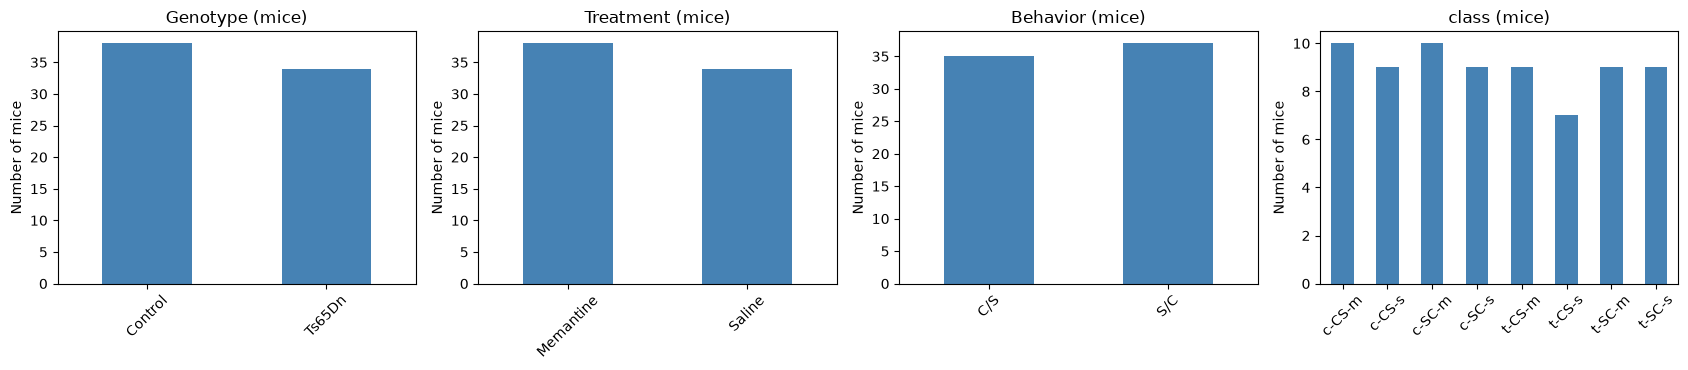

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
mice_level = df_mice.drop_duplicates("mouse_id")
for ax, col in zip(axes, ["Genotype", "Treatment", "Behavior", "class"]):
    mice_level[col].value_counts().sort_index().plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(f"{col} (mice)"); ax.set_xlabel(""); ax.set_ylabel("Number of mice")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

**Biological question:** Is the experimental design balanced, and how many independent mice does each group really contain?

**Reading:** Counted per mouse, the design is close to balanced: Control 38 vs Ts65Dn 34, Memantine 38 vs Saline 34, C/S 35 vs S/C 37. The eight classes hold 7-10 mice each (smallest: `t-CS-s`, 7). Row counts would be 15 times larger and would hide how few independent units there are.

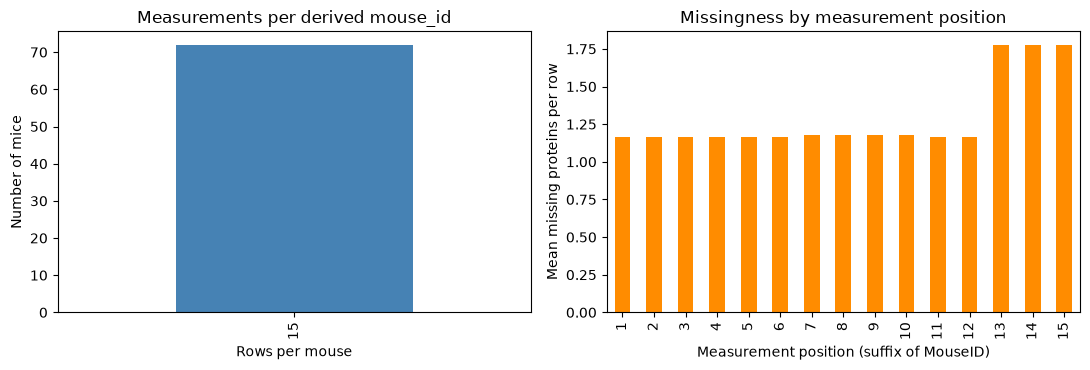

In [17]:
rows_per_mouse = df_mice.groupby("mouse_id").size()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
rows_per_mouse.value_counts().sort_index().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_xlabel("Rows per mouse"); axes[0].set_ylabel("Number of mice"); axes[0].set_title("Measurements per derived mouse_id")
df_mice.assign(n_na=X_all.isna().sum(axis=1)).groupby("meas_idx")["n_na"].mean().plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_xlabel("Measurement position (suffix of MouseID)"); axes[1].set_ylabel("Mean missing proteins per row")
axes[1].set_title("Missingness by measurement position")
plt.tight_layout(); plt.show()

**Biological question:** Does every mouse contribute equally, and is missing data spread evenly across the 15 measurement positions?

**Reading:** All 72 mice have exactly 15 rows (left). Measurement positions 13-15 have more missing proteins per row (1.78 vs about 1.17, right), but this comes entirely from one mouse: mouse 3426 has 43 missing proteins in each of those three rows. Without it, positions 13-15 are at 1.20, like the others. Missingness here is a property of individual mice, not of the measurement position.

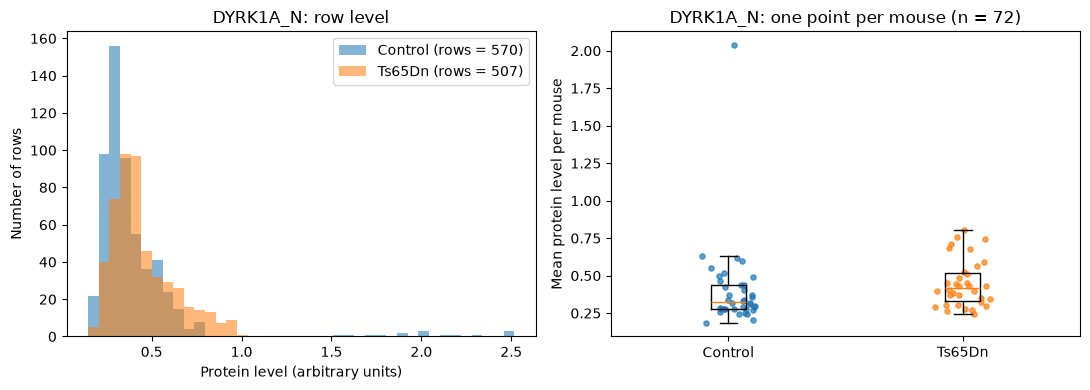

          count  median   mean
Genotype                      
Control      38   0.327  0.405
Ts65Dn       34   0.417  0.449
Most extreme mouse: 3484 | Control | mean 2.04 | x 6.2 its genotype median


In [18]:
protein = "DYRK1A_N"
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(df_mice[protein].min(), df_mice[protein].max(), 41)
for g, sub in df_mice.groupby("Genotype"):
    axes[0].hist(sub[protein].dropna(), bins=bins, alpha=0.55, label=f"{g} (rows = {sub[protein].notna().sum()})")
axes[0].set_xlabel("Protein level (arbitrary units)"); axes[0].set_ylabel("Number of rows"); axes[0].legend()
axes[0].set_title(f"{protein}: row level")

per_mouse = df_mice.groupby(["mouse_id", "Genotype"])[protein].mean().reset_index()
order = ["Control", "Ts65Dn"]
axes[1].boxplot([per_mouse.loc[per_mouse["Genotype"] == g, protein] for g in order], tick_labels=order, showfliers=False)
rng = np.random.default_rng(RANDOM_STATE)
for i, g in enumerate(order, start=1):
    v = per_mouse.loc[per_mouse["Genotype"] == g, protein]
    axes[1].scatter(i + rng.uniform(-0.12, 0.12, len(v)), v, s=14, alpha=0.7)
axes[1].set_ylabel("Mean protein level per mouse"); axes[1].set_title(f"{protein}: one point per mouse (n = 72)")
plt.tight_layout(); plt.show()
print(per_mouse.groupby("Genotype")[protein].agg(["count", "median", "mean"]).round(3))
top = per_mouse.sort_values(protein, ascending=False).iloc[0]
print("Most extreme mouse:", top["mouse_id"], "|", top["Genotype"], "| mean", round(float(top[protein]), 2),
      "| x", round(float(top[protein] / per_mouse.loc[per_mouse["Genotype"] == top["Genotype"], protein].median()), 1), "its genotype median")

**Biological question:** Is DYRK1A, encoded in the region of mouse chromosome 16 that is triplicated in Ts65Dn, higher in trisomic mice, and is that visible per mouse and not only across rows?

**Reading:** Per-mouse medians are 0.33 (Control, n = 38) and 0.42 (Ts65Dn, n = 34): a modest upward shift with large overlap. The long right tail in the row-level histogram is one animal: Control mouse 3484 has a mean of about 2.0, roughly six times its genotype median, in all 15 rows. Row-level histograms hide that this tail is a single mouse.

Explained variance ratio PC1, PC2: [0.253 0.169]


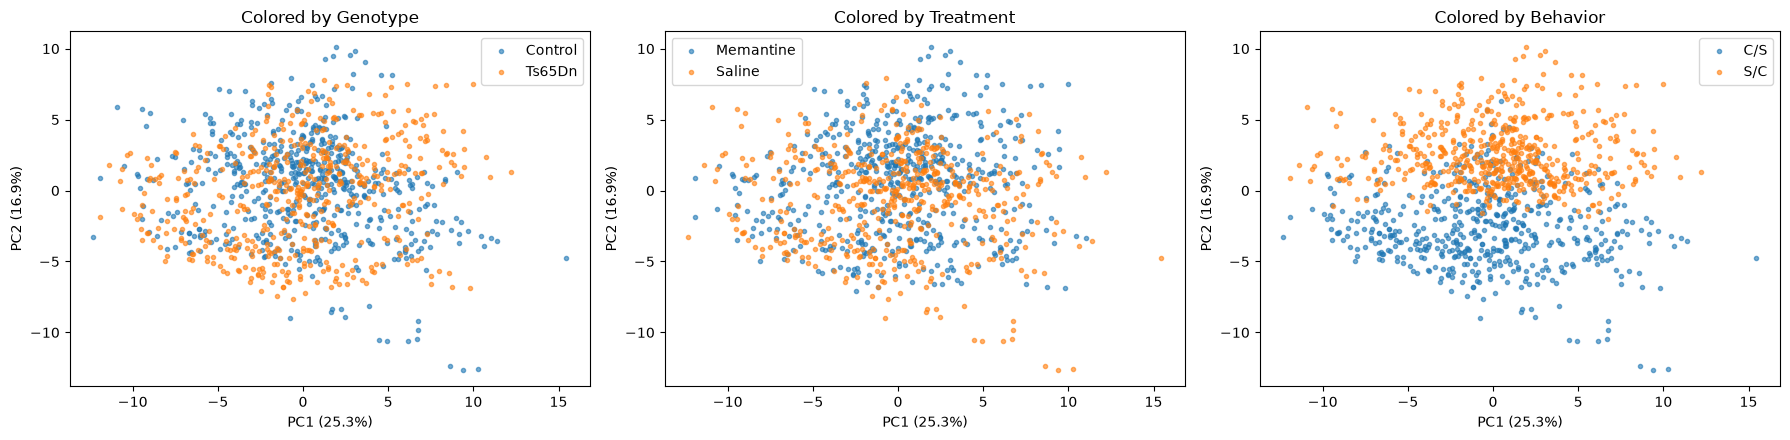

In [19]:
# EDA only: imputation + scaling here use ALL rows because no model is being evaluated.
X_scaled = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X_all))
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame({"PC1": coords[:, 0], "PC2": coords[:, 1], "Genotype": df_mice["Genotype"].values,
                       "Treatment": df_mice["Treatment"].values, "Behavior": df_mice["Behavior"].values,
                       "mouse_id": df_mice["mouse_id"].values})
print("Explained variance ratio PC1, PC2:", pca.explained_variance_ratio_.round(3))
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ["Genotype", "Treatment", "Behavior"]):
    for level, sub in pca_df.groupby(col):
        ax.scatter(sub["PC1"], sub["PC2"], s=9, alpha=0.6, label=level)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
    ax.set_title(f"Colored by {col}"); ax.legend()
plt.tight_layout(); plt.show()

**Biological question:** Do the dominant axes of protein variation reflect the experimental factors? (Exploratory only: the imputation and scaling here use all rows because no model is being evaluated.)

**Reading:** PC1 and PC2 explain 25.3% and 16.9% of the variance. Coloured by `Behavior`, the two groups separate almost cleanly along PC2 (S/C above, C/S below). `Genotype` shows partial separation with strong overlap, and `Treatment` shows little. `Behavior` is therefore the clearest structure among the three factors: a strong signal for prediction, but also a reason to ask further whether it is biological or technical. Each mouse contributes 15 points, so the density of the clouds overstates the number of independent samples.

### 3.3 Diagnostics

Report checks for:
- missingness in proteins and metadata: `Metadata: none missing. Proteins: 1396 of 83,160 cells (1.7%) are NaN, in 49 of 77 proteins and 528 of 1080 rows. Worst proteins: BCL2_N 26.4%, H3MeK4_N 25.0%, BAD_N 19.7%, EGR1_N 19.4%, H3AcK18_N 16.7%; the next, pCFOS_N, is at 6.9%. Missingness is concentrated: one row can miss up to 43 proteins, mouse 3426 alone holds 129 missing cells, and the five worst mice hold 28% of all missing cells. For BCL2_N, 17% of C/S rows but 35% of S/C rows are missing.`
- duplicate rows or duplicate measurement identifiers: `None. 0 duplicate rows, 0 duplicated MouseID, and no two rows identical at 3 decimals. One pair of protein columns is identical: ARC_N and pS6_N.` 
- expected 15 measurements per mouse: `Confirmed: all 72 mice have exactly 15 rows.` 
- unusual categories or inconsistent labels: `None. Genotype and Treatment and Behavior have two levels each, class has eight, spelling is consistent, and every label is constant within a mouse.` 
- non-finite, negative, or implausible expression values: `No infinities, no zeros, no constant columns. One negative protein-level value (RRP1_N, row 298, -0.062), which cannot be a true level; its cause is not documented, so it is left unchanged. Values range up to 8.48 (NR2A_N). Mouse 3484 has extreme levels of a group of proteins (mouse-level means of DYRK1A_N, BRAF_N, pERK_N, ITSN1_N and pELK_N are 5.7-6.9 standard deviations above the overall median).` 
- highly correlated or redundant protein variables: `10 protein pairs have |r| > 0.9 and 3 have |r| > 0.95. The top pair, ARC_N and pS6_N (r = 1.000), is an exact duplicate. After removing pS6_N, 9 pairs exceed 0.9 and 2 exceed 0.95 (DYRK1A_N with BRAF_N and ITSN1_N, r = 0.96); without the extreme mouse 3484 these fall to 6 and 0, so the strongest correlations are partly driven by that one mouse, but the redundancy among the DYRK1A_N group remains (r of 0.91-0.93).` 
- predictors that are deterministic parts of the target: `Yes. class is fully determined by Genotype, Treatment and Behavior (each class maps to exactly one combination), so class contains the target Behavior; Genotype and Treatment are also components of class. MouseID and mouse_id identify the animal and therefore its label. None of the 77 protein columns is a deterministic part of the target.`

In [ ]:
# 1-2 missingness and duplicates
print("Metadata NaN:", int(df_mice[meta_cols].isna().sum().sum()), "| protein NaN cells:", int(X_all.isna().sum().sum()),
      "| duplicate rows:", int(df_mice.duplicated().sum()), "| duplicate MouseID:", int(df_mice["MouseID"].duplicated().sum()))
# 3 repeated measurements per mouse
print("Rows per mouse:", df_mice.groupby("mouse_id").size().value_counts().to_dict())
# 4 labels
for c in ["Genotype", "Treatment", "Behavior", "class"]:
    print(c, df_mice[c].value_counts(dropna=False).to_dict())
# 5 values
print("Infinite:", int(np.isinf(X_all.to_numpy(dtype=float)).sum()), "| negative:", int((X_all < 0).sum().sum()),
      "| min:", round(float(X_all.min().min()), 4), f"(at {X_all.stack().idxmin()})", "| max:", round(float(X_all.max().max()), 3))
# 6 correlation
corr = X_all.corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
display(pairs.head(8).round(3).to_frame("|r|"))
print("Pairs with |r| > 0.9:", int((pairs > 0.9).sum()), "| > 0.95:", int((pairs > 0.95).sum()))
print("ARC_N identical to pS6_N:", X_all["ARC_N"].equals(X_all["pS6_N"]), "| max absolute difference:", float((X_all["ARC_N"] - X_all["pS6_N"]).abs().max()))
# 6b are the strongest correlations driven by one extreme mouse?
extreme_mouse = df_mice.groupby("mouse_id")["DYRK1A_N"].mean().idxmax()
cols76 = [c for c in protein_cols if c != "pS6_N"]
def n_pairs(d):
    c = d[cols76].corr().abs()
    p = c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack()
    return int((p > 0.9).sum()), int((p > 0.95).sum())
print("After removing pS6_N, pairs |r| > 0.9 / > 0.95:", n_pairs(df_mice),
      "| without mouse", extreme_mouse, ":", n_pairs(df_mice[df_mice["mouse_id"] != extreme_mouse]))
# 7 deterministic parts of the target
display(pd.crosstab(df_mice["class"], [df_mice["Genotype"], df_mice["Treatment"], df_mice["Behavior"]]))
print("Max distinct Genotype/Treatment/Behavior per class:", df_mice.groupby("class")[["Genotype", "Treatment", "Behavior"]].nunique().max().to_dict())

Metadata NaN: 0 | protein NaN cells: 1396 | duplicate rows: 0 | duplicate MouseID: 0
Rows per mouse: {15: 72}
Genotype {'Control': 570, 'Ts65Dn': 510}
Treatment {'Memantine': 570, 'Saline': 510}
Behavior {'S/C': 555, 'C/S': 525}
class {'c-CS-m': 150, 'c-SC-m': 150, 'c-CS-s': 135, 'c-SC-s': 135, 't-CS-m': 135, 't-SC-m': 135, 't-SC-s': 135, 't-CS-s': 105}
Infinite: 0 | negative: 1 | min: -0.062 (at (298, 'RRP1_N')) | max: 8.483


|r|
ARC_N    pS6_N       1.000
DYRK1A_N BRAF_N      0.960
         ITSN1_N     0.960
NR1_N    pNR1_N      0.948
DYRK1A_N pERK_N      0.946
pERK_N   BRAF_N      0.927
ITSN1_N  BRAF_N      0.918
NR1_N    Bcatenin_N  0.915

Pairs with |r| > 0.9: 10 | > 0.95: 3
ARC_N identical to pS6_N: True | max absolute difference: 0.0
After removing pS6_N, pairs |r| > 0.9 / > 0.95: (9, 2) | without mouse 3484 : (6, 0)


Genotype    Control                     Ts65Dn                 
Treatment Memantine      Saline      Memantine      Saline     
Behavior        C/S  S/C    C/S  S/C       C/S  S/C    C/S  S/C
class                                                          
c-CS-m          150    0      0    0         0    0      0    0
c-CS-s            0    0    135    0         0    0      0    0
c-SC-m            0  150      0    0         0    0      0    0
c-SC-s            0    0      0  135         0    0      0    0
t-CS-m            0    0      0    0       135    0      0    0
t-CS-s            0    0      0    0         0    0    105    0
t-SC-m            0    0      0    0         0  135      0    0
t-SC-s            0    0      0    0         0    0      0  135

Max distinct Genotype/Treatment/Behavior per class: {'Genotype': 1, 'Treatment': 1, 'Behavior': 1}


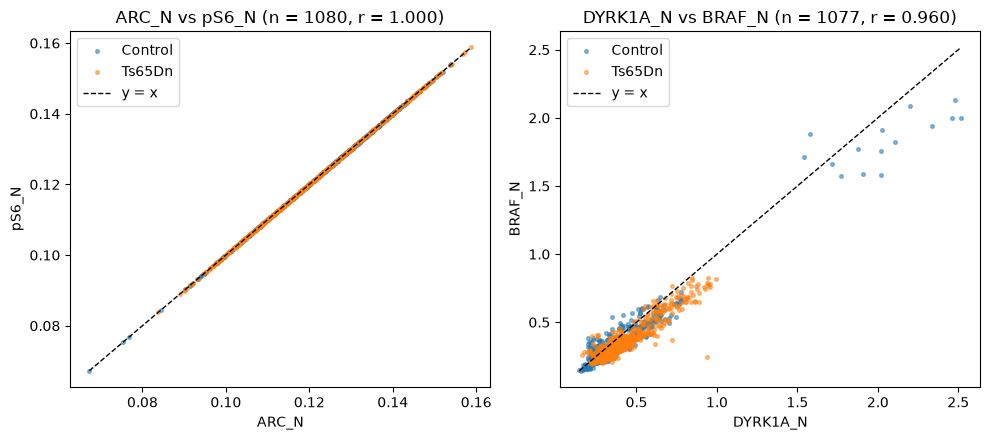

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (a, b) in zip(axes, [("ARC_N", "pS6_N"), ("DYRK1A_N", "BRAF_N")]):
    pair = df_mice[[a, b, "Genotype"]].dropna()
    for g, sub in pair.groupby("Genotype"):
        ax.scatter(sub[a], sub[b], s=7, alpha=0.5, label=g)
    lims = [pair[[a, b]].min().min(), pair[[a, b]].max().max()]
    ax.plot(lims, lims, "k--", lw=1, label="y = x")
    ax.set_xlabel(a); ax.set_ylabel(b); ax.set_title(f"{a} vs {b} (n = {len(pair)}, r = {pair[a].corr(pair[b]):.3f})"); ax.legend()
plt.tight_layout(); plt.show()

**Biological question:** Are any protein variables redundant, and is the redundancy real?

**Reading:** `ARC_N` and `pS6_N` lie exactly on the line y = x: they are identical in all 1080 rows (maximum difference 0). Two different proteins should not be numerically identical, so this looks like a duplicated column in the distributed file (the cause is unknown). `pS6_N` is removed, leaving 76 candidate proteins. `DYRK1A_N` vs `BRAF_N` is tight but not identical (r = 0.96).

### 3.4 Preparation and feature roles

Selected supervised-learning question: **Can the levels of cortex nuclear proteins predict the `Behavior` label (C/S vs S/C) of a mouse that was not used for training?** Target `y` = `Behavior`; features `X` = protein-level columns only.

Missing-value decision: **remove proteins that are missing in more than 10% of training rows, then impute the remaining missing cells with the training-set median.** The table compares this with the alternatives.

In [22]:
# Candidate columns after removing the exact duplicate pS6_N
df_clean = df_mice.drop(columns=["pS6_N"])
protein_cols_clean = [c for c in protein_cols if c != "pS6_N"]
X = df_clean[protein_cols_clean].copy()
y = df_clean["Behavior"].copy()
groups = df_clean["mouse_id"].copy()

# Split first
sgkf = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(X, df_clean["class"], groups=groups))
X_train_raw, X_test_raw = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

def summarize(name, Xtr, Xte, ytr, n_imputed=0):
    return {"rule": name, "train rows": len(Xtr), "test rows": len(Xte),
            "train mice": groups.loc[Xtr.index].nunique(), "test mice": groups.loc[Xte.index].nunique(),
            "proteins": Xtr.shape[1], "imputed train cells": n_imputed,
            "train C/S : S/C": f"{(ytr == 'C/S').sum()} : {(ytr == 'S/C').sum()}"}

frac = X_train_raw.isna().mean()
keep_cols = frac[frac <= 0.10].index                      # learned on training rows only
rows = []

ok_tr, ok_te = X_train_raw.notna().all(axis=1), X_test_raw.notna().all(axis=1)
rows.append(summarize("1. drop every row with any NaN (76 proteins)", X_train_raw[ok_tr], X_test_raw[ok_te], y_train[ok_tr]))

full_cols = X_train_raw.columns[X_train_raw.notna().all()]
rows.append(summarize("2. drop every protein with any NaN", X_train_raw[full_cols], X_test_raw[full_cols], y_train))

A_tr, A_te = X_train_raw[keep_cols], X_test_raw[keep_cols]
okA_tr, okA_te = A_tr.notna().all(axis=1), A_te.notna().all(axis=1)
rows.append(summarize("3. drop proteins >10% missing, then incomplete rows", A_tr[okA_tr], A_te[okA_te], y_train[okA_tr]))

rows.append(summarize("4. impute all 76 proteins (median)", X_train_raw, X_test_raw, y_train, int(X_train_raw.isna().sum().sum())))
rows.append(summarize("5. CHOSEN: drop proteins >10% missing + median imputation", A_tr, A_te, y_train, int(A_tr.isna().sum().sum())))
display(pd.DataFrame(rows).set_index("rule"))
print("Removed for >10% missing in training rows:", list(frac[frac > 0.10].index))
print("Next most missing:", frac.sort_values(ascending=False).iloc[5:7].round(3).to_dict())

# Chosen rule: fit the imputer on the training data only, apply to both
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw[keep_cols]), columns=keep_cols, index=X_train_raw.index)
X_test = pd.DataFrame(imputer.transform(X_test_raw[keep_cols]), columns=keep_cols, index=X_test_raw.index)

print("\nX_train:", X_train.shape, "| X_test:", X_test.shape, "| y_train:", y_train.shape, "| y_test:", y_test.shape)
assert set(groups.iloc[train_idx]).isdisjoint(groups.iloc[test_idx])
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0
assert list(X_train.columns) == list(X_test.columns)

,train rows,test rows,train mice,test mice,proteins,imputed train cells,train C/S : S/C
rule,,,,,,,
1. drop every row with any NaN (76 proteins),432,120,29,8,76,0,225 : 207
2. drop every protein with any NaN,810,270,54,18,27,0,390 : 420
"3. drop proteins >10% missing, then incomplete rows",747,225,50,15,71,0,330 : 417
4. impute all 76 proteins (median),810,270,54,18,76,1156,390 : 420
5. CHOSEN: drop proteins >10% missing + median imputation,810,270,54,18,71,193,390 : 420


Removed for >10% missing in training rows: ['BAD_N', 'BCL2_N', 'H3AcK18_N', 'EGR1_N', 'H3MeK4_N']
Next most missing: {'pCFOS_N': 0.056, 'ELK_N': 0.022}

X_train: (810, 71) | X_test: (270, 71) | y_train: (810,) | y_test: (270,)


In [23]:
removed_missing = list(frac[frac > 0.10].index)
roles = pd.DataFrame([
    ("protein features kept", len(keep_cols), "X (features)", "Measured protein levels with <=10% missing in training rows; remaining NaN imputed with the training median"),
    ("5 proteins removed: " + ", ".join(removed_missing), len(removed_missing), "excluded", ">10% missing in training rows; BCL2_N missingness differs by Behavior (see 3.6 / section 2)"),
    ("pS6_N", 1, "excluded", "exact duplicate of ARC_N in all 1080 rows"),
    ("Behavior", 1, "target (y)", "label to predict"),
    ("class", 1, "excluded", "composite of Genotype, Treatment and Behavior, so it contains the target"),
    ("Genotype, Treatment", 2, "excluded", "experimental-design variables, not protein measurements; the question asks whether proteins alone predict Behavior"),
    ("MouseID", 1, "excluded", "identifier of a measurement record (encodes which mouse the row belongs to)"),
    ("mouse_id", 1, "grouping variable", "independent biological unit; used only as groups= in the split, never as a feature"),
], columns=["column(s)", "n", "role", "reason"])
display(roles)
assert roles["n"].sum() == df_mice.drop(columns="meas_idx").shape[1], "every column must have exactly one role"
print("Columns accounted for:", int(roles["n"].sum()), "of", df_mice.drop(columns="meas_idx").shape[1])

,column(s),n,role,reason
0,protein features kept,71,X (features),Measured protein levels with <=10% missing in ...
1,"5 proteins removed: BAD_N, BCL2_N, H3AcK18_N, ...",5,excluded,>10% missing in training rows; BCL2_N missingn...
2,pS6_N,1,excluded,exact duplicate of ARC_N in all 1080 rows
3,Behavior,1,target (y),label to predict
4,class,1,excluded,"composite of Genotype, Treatment and Behavior,..."
5,"Genotype, Treatment",2,excluded,"experimental-design variables, not protein mea..."
6,MouseID,1,excluded,identifier of a measurement record (encodes wh...
7,mouse_id,1,grouping variable,independent biological unit; used only as grou...


Columns accounted for: 83 of 83


**Why the missing-value rule was chosen.**
- Dropping every row with any NaN keeps only 402 of 810 training rows and 27 of 54 training mice; it also removes 120 of the 270 test rows, which cannot be done to new samples in real use.
- Dropping every protein with any NaN keeps only 27 of 76 proteins.
- Dropping the five worst proteins and then every incomplete row loses a further 108 training rows and 7 training mice.
- Imputing all 76 proteins fills 1096 training cells, including 18-26% of the training values of five proteins, which then largely reflect the imputation rule.
- The chosen rule removes the five proteins that are 17-26% missing, keeps all training mice and imputes only 238 cells (0.4% of the training matrix).

The 10% cut-off is a choice, not a derived value. In the training rows the next protein, `pCFOS_N`, is at 9.3% (6.9% over all rows), just under the cut-off, so a lower threshold would also remove it. Separately, `BCL2_N` is missing more often in S/C rows than in C/S rows, so keeping and imputing it would hide a pattern related to the target.

**Excluded variables and why:**
- `MouseID` and `mouse_id`: identifiers. The raw ID labels a measurement record and the derived ID labels the biological unit; neither is a feature, and `mouse_id` is used only as the grouping variable for the split.
- `Behavior`: it is the target.
- `class`: it is built from Genotype, Treatment and Behavior, so it contains the target.
- `Genotype` and `Treatment`: experimental-design variables, not protein measurements. They are balanced across `Behavior`, but the question asks whether proteins alone carry the signal.
- `pS6_N`: exact duplicate of `ARC_N`.
- `BCL2_N`, `H3MeK4_N`, `BAD_N`, `EGR1_N`, `H3AcK18_N`: more than 10% missing in the training rows.

**Deliverable:** `X_train` (810 x 71), `X_test` (270 x 71), `y_train` (810), `y_test` (270), created in the cell above.

### 3.5 Split strategy
- Independent biological unit: `[mouse]`
- Grouping variable: `[mouse_id]`
- Split method: `StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=230926)`. First fold used as the test set, stratified on the composite `class`; it gives 54 training mice (810 rows) and 18 test mice (270 rows).


**Why a row-wise random split would be bad idea:** the 15 rows of a mouse are technical replicates and are far more alike than rows of different mice (median 72% of a protein's variance is explained by mouse identity). In a row-wise split, a near-copy of every test row would sit in the training set, so the model could recognise the mouse instead of learning the biology. Section 3.6 shows that even missingness indicators alone score 0.64 row-wise but only 0.49 (chance) when mice are kept together.

### 3.6 Confounding and distribution structure

Investigate associations between the target and:
- treatment 
- behavior 
- genotype 
- composite class 
- number of measurements per mouse.

In [24]:
mice_level = df_clean.drop_duplicates("mouse_id")
for col in ["Treatment", "Behavior"]:
    t = pd.crosstab(mice_level["Genotype"], mice_level[col])
    print(f"Genotype x {col} (mice):"); display(t)
    print("Row proportions:"); display(pd.crosstab(mice_level["Genotype"], mice_level[col], normalize="index").round(2))
    print(f"Fisher exact p = {fisher_exact(t)[1]:.3f}\n")
for col in ["Genotype", "Treatment"]:
    print(f"Target Behavior x {col} (mice):"); display(pd.crosstab(mice_level["Behavior"], mice_level[col]))
print("class vs target Behavior (rows):"); display(pd.crosstab(df_clean["class"], df_clean["Behavior"]))
parts = []
for col in ["Genotype", "Treatment", "Behavior", "class"]:
    t = df_clean.groupby(col).agg(mice=("mouse_id", "nunique"), rows=("mouse_id", "size"))
    t["rows_per_mouse"] = t["rows"] / t["mice"]
    parts.append(t)
display(pd.concat(parts, keys=["Genotype", "Treatment", "Behavior", "class"]))

Genotype x Treatment (mice):


Treatment,Memantine,Saline
Genotype,,
Control,20,18
Ts65Dn,18,16


Row proportions:


Treatment,Memantine,Saline
Genotype,,
Control,0.53,0.47
Ts65Dn,0.53,0.47


Fisher exact p = 1.000

Genotype x Behavior (mice):


...

Target Behavior x Treatment (mice):


Treatment,Memantine,Saline
Behavior,,
C/S,19,16
S/C,19,18


class vs target Behavior (rows):


Behavior,C/S,S/C
class,,
c-CS-m,150,0
c-CS-s,135,0
c-SC-m,0,150
c-SC-s,0,135
t-CS-m,135,0
t-CS-s,105,0
t-SC-m,0,135
t-SC-s,0,135


mice  rows  rows_per_mouse
Genotype  Control      38   570            15.0
          Ts65Dn       34   510            15.0
Treatment Memantine    38   570            15.0
          Saline       34   510            15.0
Behavior  C/S          35   525            15.0
          S/C          37   555            15.0
class     c-CS-m       10   150            15.0
          c-CS-s        9   135            15.0
          c-SC-m       10   150            15.0
          c-SC-s        9   135            15.0
          t-CS-m        9   135            15.0
          t-CS-s        7   105            15.0
          t-SC-m        9   135            15.0
          t-SC-s        9   135            15.0

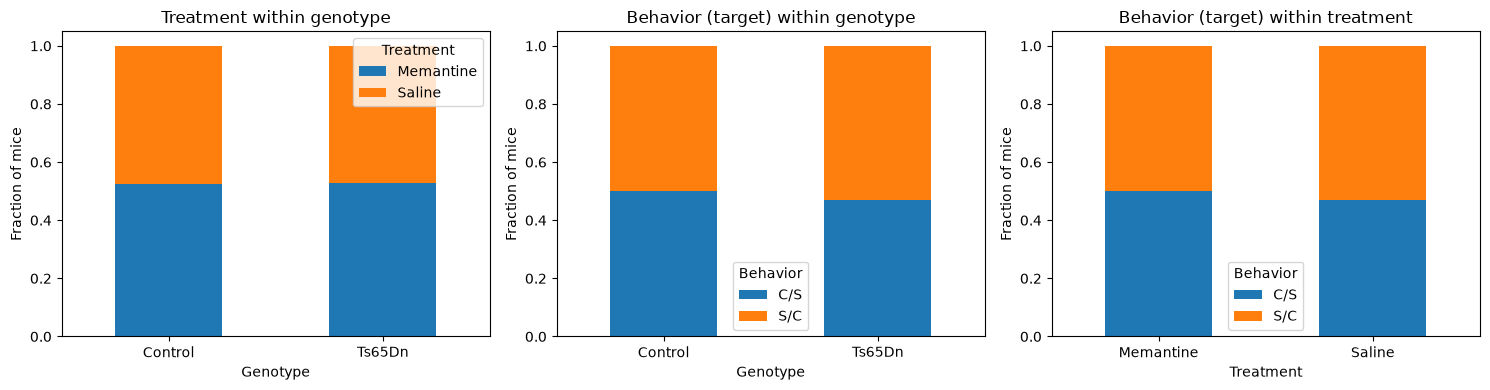

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ct = pd.crosstab(mice_level["Genotype"], mice_level["Treatment"], normalize="index")
ct.plot(kind="bar", stacked=True, ax=axes[0]); axes[0].set_ylabel("Fraction of mice"); axes[0].set_title("Treatment within genotype")
ct = pd.crosstab(mice_level["Genotype"], mice_level["Behavior"], normalize="index")
ct.plot(kind="bar", stacked=True, ax=axes[1]); axes[1].set_ylabel("Fraction of mice"); axes[1].set_title("Behavior (target) within genotype")
ct = pd.crosstab(mice_level["Treatment"], mice_level["Behavior"], normalize="index")
ct.plot(kind="bar", stacked=True, ax=axes[2]); axes[2].set_ylabel("Fraction of mice"); axes[2].set_title("Behavior (target) within treatment")
for ax in axes: ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

**Plausible sources of confounding, leakage or distribution shift:**
1. **Unrecorded technical structure (batch).** A grouped accuracy of 0.99 for an experimental label is unusually high. The file has no batch, date or plate column, so it cannot be decided whether the proteins separate `Behavior` because of biology or because behavior groups were processed in different runs. `Genotype` and `Treatment` cannot explain it, because they are balanced across `Behavior`.
2. **Mouse identity under a row-wise split** (leakage, shown above).
3. **Missingness related to the target:** `BCL2_N` is missing in 17% of C/S rows and 35% of S/C rows.
4. **One extreme mouse (3484)** with very high levels of a correlated group of proteins in all 15 rows; with only 72 mice, whether it falls in the training or the test set can shift results.

## Deliverable summary and decision record

**ML question.** Can the levels of 71 cortex nuclear proteins predict the `Behavior` label (C/S vs S/C) of an unseen mouse?

**Biological unit.** The mouse (72 mice). Each of the 1080 rows is a technical RPPA measurement (5 dilution points x 3 replicate spots per mouse), not an independent observation.

**Observations and features.** 1080 rows; 77 protein columns in the file, 71 used after removing one exact duplicate and five proteins with more than 10% missing training values. `X_train` is 810 x 71, `X_test` is 270 x 71.

**Missing-value decision.** Proteins missing in more than 10% of training rows are removed; the remaining 238 missing training cells are imputed with the training median (fitted on training mice only).

**Replicate and grouping decision.** All 15 rows of a mouse are kept together via `mouse_id`.

**Split strategy.** Mouse-grouped `StratifiedGroupKFold` (4 folds, first fold as test, stratified on `class`), 54 training and 18 test mice, no mouse in both.

**One potential source of bias, confounding or leakage.** The file records no batch or run variable, so the near-perfect separation of `Behavior` by proteins cannot be attributed to biology with certainty; it could partly reflect technical processing differences. (Row-wise splitting would additionally leak mouse identity.)

**Unresolved data-quality concerns:**
- `ARC_N` and `pS6_N` are identical in all rows; the cause is unknown and `pS6_N` was removed.
- One negative protein-level value (`RRP1_N`, row 298, -0.062); cause undocumented; the value was left unchanged and kept in the data.
- Upstream normalisation, units and the meaning of the `_N` suffix are not documented.
- Mouse 3484 has extreme levels of several proteins; mouse 3426 has 43 missing proteins in each of three rows. Neither was removed.
- The 10% missingness cut-off is a choice.
- No batch, sex, age or litter information, so those confounders cannot be assessed.
- Only 18 test mice: a single test score will be noisy; results should be reported across folds.
- The preprocessing is scripted and fitted on the training mice only but is not wrapped in a single `Pipeline` object.